### 1.Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("Library berhasil diimport.")

Library berhasil diimport.


### 2. Load Dataset

In [2]:
df = pd.read_csv('CKD.csv', sep=';')
print(f"Dimensi Data Mentah : {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"\nDaftar Kolom ({len(df.columns)} total):")
print(df.columns.tolist())

Dimensi Data Mentah : 1659 baris x 54 kolom

Daftar Kolom (54 total):
['PatientID', 'Age', 'Gender', 'Ethnicity', 'SocioeconomicStatus', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension', 'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'SystolicBP', 'DiastolicBP', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'ACEInhibitors', 'Diuretics', 'NSAIDsUse', 'Statins', 'AntidiabeticMedications', 'Edema', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore', 'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality', 'MedicalCheckupsFrequency'

In [3]:
df.head()

,PatientID,Age,Gender,Ethnicity,SocioeconomicStatus,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,...,Itching,QualityOfLifeScore,HeavyMetalsExposure,OccupationalExposureChemicals,WaterQuality,MedicalCheckupsFrequency,MedicationAdherence,HealthLiteracy,Diagnosis,DoctorInCharge
0,1,71,0,0,0,2,31.069414,1,5.128112,1.676220,...,7.556302,76.076800,0,0,1,1.018824,4.966808,9.871449,1,Confidential
1,2,34,0,0,1,3,29.692119,1,18.609552,8.377574,...,6.836766,40.128498,0,0,0,3.923538,8.189275,7.161765,1,Confidential
2,3,80,1,1,0,1,37.394822,1,11.882429,9.607401,...,2.144722,92.872842,0,1,1,1.429906,7.624028,7.354632,1,Confidential
3,4,40,0,2,0,1,31.329680,0,16.020165,0.408871,...,7.077188,90.080321,0,0,0,3.226416,3.282688,6.629587,1,Confidential
4,5,43,0,1,1,2,23.726311,0,7.944146,0.780319,...,3.553118,5.258372,0,0,1,0.285466,3.849498,1.437385,1,Confidential


### 3. Data Cleaning - Drop Fitur yang tidak digunakan

In [4]:
df_model = df.copy()

drop_cols = [
    'PatientID',
    'DoctorInCharge'
]

df_model = df_model.drop(columns=drop_cols)

print("Ukuran data setelah drop kolom:")
print(f"{df_model.shape[0]} baris x {df_model.shape[1]} kolom")

Ukuran data setelah drop kolom:
1659 baris x 52 kolom


### 4. Klasifikasi Tipe Fitur

In [5]:
target = 'Diagnosis'

# ------------------------------------------
# Fitur Biner
# ------------------------------------------

binary_cols = [
    'Gender',
    'Smoking',
    'FamilyHistoryKidneyDisease',
    'FamilyHistoryHypertension',
    'FamilyHistoryDiabetes',
    'PreviousAcuteKidneyInjury',
    'UrinaryTractInfections',
    'ACEInhibitors',
    'Diuretics',
    'Statins',
    'AntidiabeticMedications',
    'Edema',
    'HeavyMetalsExposure',
    'OccupationalExposureChemicals',
    'WaterQuality'
]


# ------------------------------------------
# Fitur Kategorikal Non-Biner
# ------------------------------------------

categorical_cols = [
    'Ethnicity',
    'SocioeconomicStatus',
    'EducationLevel'
]


# ------------------------------------------
# Fitur Numerik Kontinu
# ------------------------------------------

continuous_cols = [
    col
    for col in df_model.columns
    if (
        col != target
        and col not in binary_cols
        and col not in categorical_cols
    )
]


# ------------------------------------------
# Tampilkan hasil
# ------------------------------------------

print(
    f"Fitur Biner              : "
    f"{len(binary_cols)} fitur"
)

print(binary_cols)

print()

print(
    f"Fitur Kategorikal        : "
    f"{len(categorical_cols)} fitur"
)

print(categorical_cols)

print()

print(
    f"Fitur Numerik Kontinu    : "
    f"{len(continuous_cols)} fitur"
)

print(continuous_cols)

print()

print(
    f"Target Variabel          : "
    f"{target}"
)

print(
    f"Total fitur prediktif    : "
    f"{len(binary_cols) + len(categorical_cols) + len(continuous_cols)} fitur"
)

Fitur Biner              : 15 fitur
['Gender', 'Smoking', 'FamilyHistoryKidneyDisease', 'FamilyHistoryHypertension', 'FamilyHistoryDiabetes', 'PreviousAcuteKidneyInjury', 'UrinaryTractInfections', 'ACEInhibitors', 'Diuretics', 'Statins', 'AntidiabeticMedications', 'Edema', 'HeavyMetalsExposure', 'OccupationalExposureChemicals', 'WaterQuality']

Fitur Kategorikal        : 3 fitur
['Ethnicity', 'SocioeconomicStatus', 'EducationLevel']

Fitur Numerik Kontinu    : 33 fitur
['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'FastingBloodSugar', 'HbA1c', 'SerumCreatinine', 'BUNLevels', 'GFR', 'ProteinInUrine', 'ACR', 'SerumElectrolytesSodium', 'SerumElectrolytesPotassium', 'SerumElectrolytesCalcium', 'SerumElectrolytesPhosphorus', 'HemoglobinLevels', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'NSAIDsUse', 'FatigueLevels', 'NauseaVomiting', 'MuscleCramps', 'Itching', 'QualityOfLifeScore'

## 5. Exploratory Data Analysis (EDA)

### 5.1 Pengecekan Tipe Data

In [6]:

print("===== TIPE DATA SETIAP FITUR =====")
print(df_model.dtypes)

print("\n===== KOLOM NON-NUMERIK =====")

non_numeric_cols = df_model.select_dtypes(
    exclude=np.number
).columns.tolist()

print(non_numeric_cols)

if len(non_numeric_cols) == 0:
    print("Semua fitur sudah bertipe numerik.")
else:
    print(
        "Terdapat fitur non-numerik yang perlu dilakukan encoding."
    )

===== TIPE DATA SETIAP FITUR =====
Age                                int64
Gender                             int64
Ethnicity                          int64
SocioeconomicStatus                int64
EducationLevel                     int64
BMI                              float64
Smoking                            int64
AlcoholConsumption               float64
PhysicalActivity                 float64
DietQuality                      float64
SleepQuality                     float64
FamilyHistoryKidneyDisease         int64
FamilyHistoryHypertension          int64
FamilyHistoryDiabetes              int64
PreviousAcuteKidneyInjury          int64
UrinaryTractInfections             int64
SystolicBP                         int64
DiastolicBP                        int64
FastingBloodSugar                float64
HbA1c                            float64
SerumCreatinine                  float64
BUNLevels                        float64
GFR                              float64
ProteinInUrine        

### 5.2 Pengecekan Missing Value

In [7]:
print("Total missing value pada dataset:")
print(df_model.isnull().sum().sum())

Total missing value pada dataset:
0


### 5.3 Statistika Deskriptif

In [8]:
desc = df_model[continuous_cols].describe().T
desc.columns = ['count', 'mean', 'std', 'min', '25%', 'median (50%)', '75%', 'max']
display(desc.round(3))

,count,mean,std,min,25%,median (50%),75%,max
Age,1659.0,54.441,20.550,20.000,36.000,54.000,72.000,90.000
BMI,1659.0,27.620,7.289,15.034,21.471,27.652,34.016,39.994
AlcoholConsumption,1659.0,9.970,5.799,0.022,5.051,9.952,14.967,19.993
PhysicalActivity,1659.0,5.024,2.866,0.001,2.555,5.072,7.461,9.998
DietQuality,1659.0,5.029,2.866,0.002,2.558,4.990,7.428,9.999
SleepQuality,1659.0,6.942,1.704,4.001,5.487,6.933,8.346,9.984
SystolicBP,1659.0,134.392,25.768,90.000,113.000,134.000,157.000,179.000
DiastolicBP,1659.0,89.313,17.354,60.000,75.000,89.000,104.000,119.000
FastingBloodSugar,1659.0,132.529,36.563,70.045,100.505,131.478,163.108,199.960
HbA1c,1659.0,6.984,1.735,4.000,5.495,6.988,8.524,9.998


### 5.4  Distribusi Variabel Target — Class Imbalance

===== DISTRIBUSI TARGET =====

Non-CKD (0) : 135 pasien (8.1%)
CKD (1)     : 1524 pasien (91.9%)
Rasio imbalance (1:0) : 11.3x


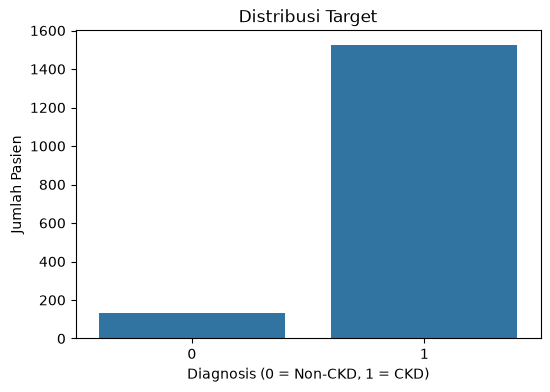

In [9]:

diagnosis_counts = (
    df_model[target]
    .value_counts()
    .sort_index()
)

imbalance_ratio = (
    diagnosis_counts[1] / diagnosis_counts[0]
)

print("===== DISTRIBUSI TARGET =====")
print()

print(
    f"Non-CKD (0) : "
    f"{diagnosis_counts[0]} pasien "
    f"({diagnosis_counts[0] / len(df_model) * 100:.1f}%)"
)

print(
    f"CKD (1)     : "
    f"{diagnosis_counts[1]} pasien "
    f"({diagnosis_counts[1] / len(df_model) * 100:.1f}%)"
)

print(
    f"Rasio imbalance (1:0) : "
    f"{imbalance_ratio:.1f}x"
)

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_model,
    x=target
)

plt.title("Distribusi Target")
plt.xlabel("Diagnosis (0 = Non-CKD, 1 = CKD)")
plt.ylabel("Jumlah Pasien")

plt.show()

### 5.5 Distribusi Fitur Numerik

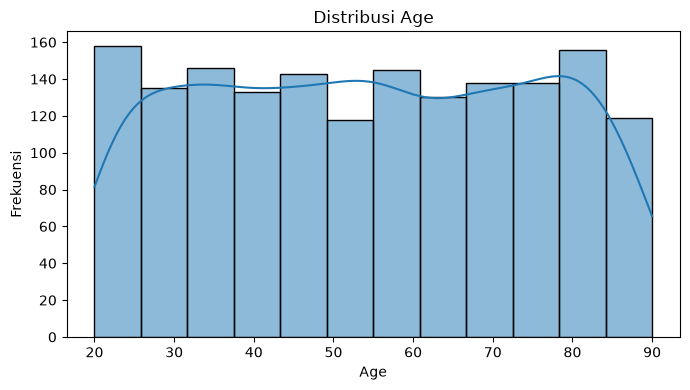

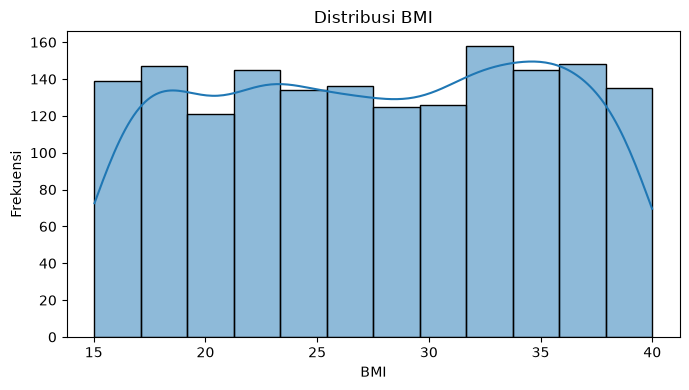

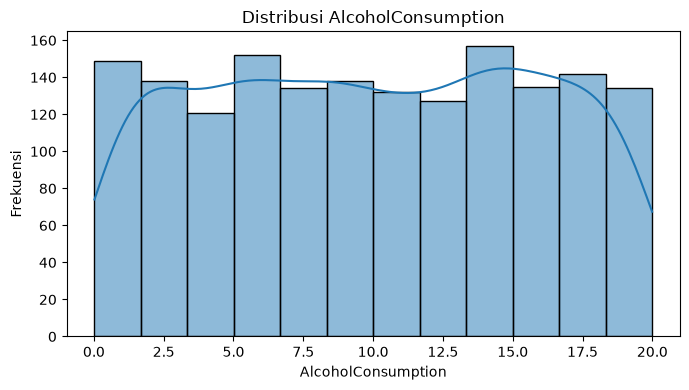

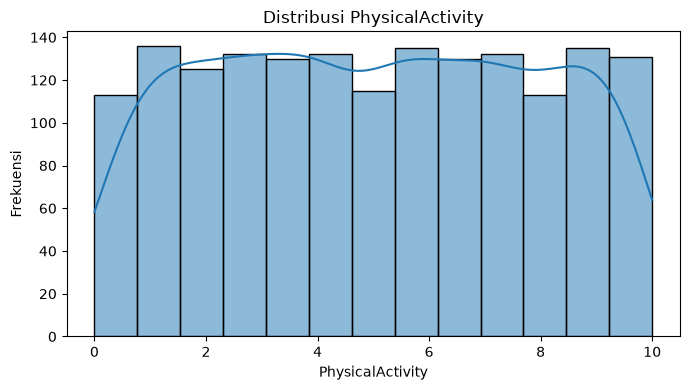

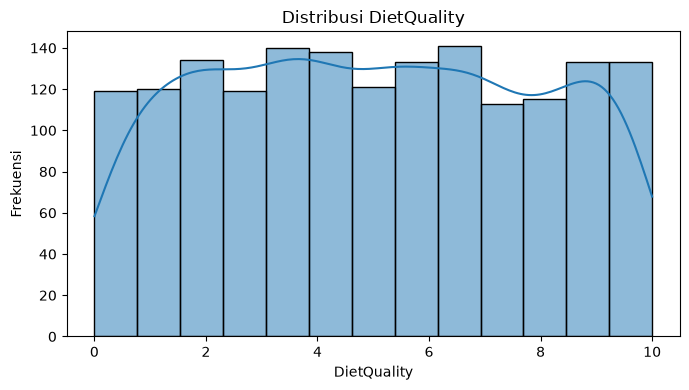

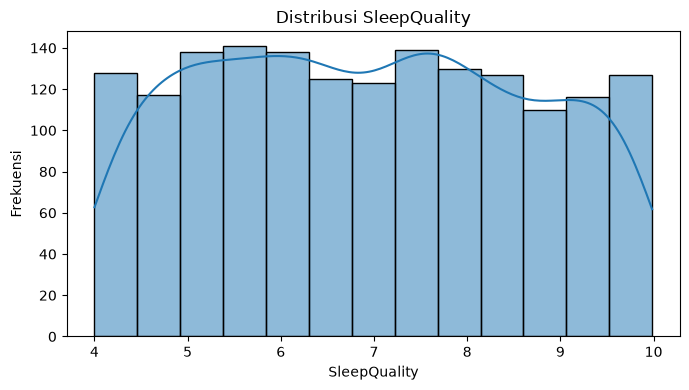

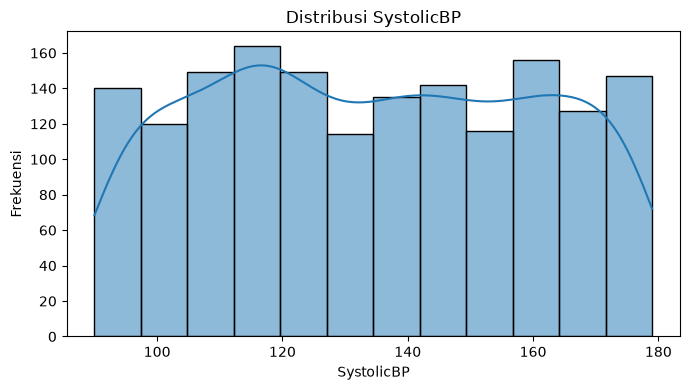

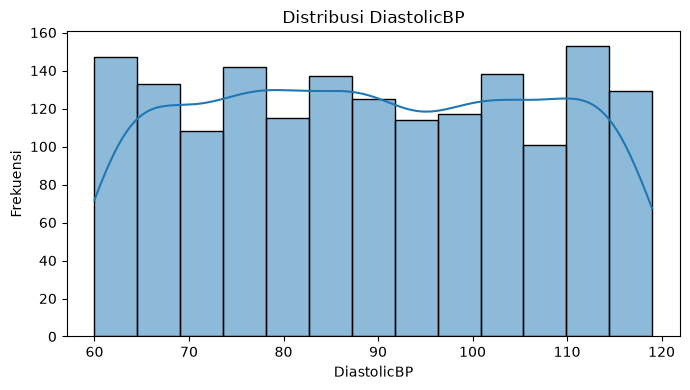

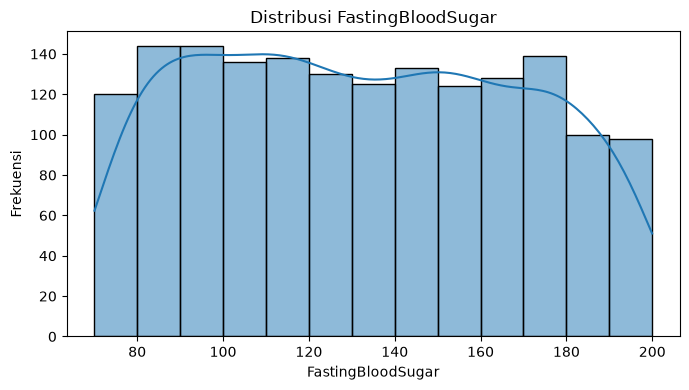

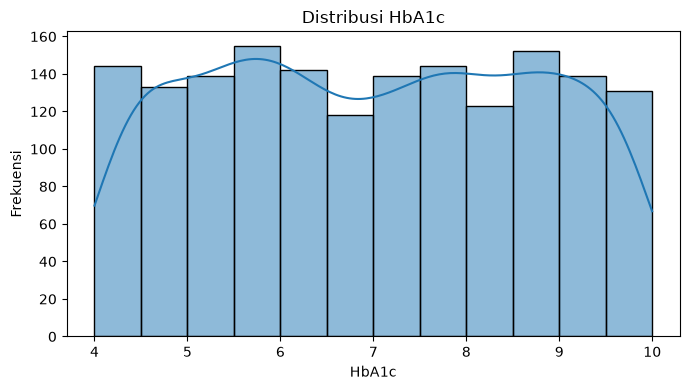

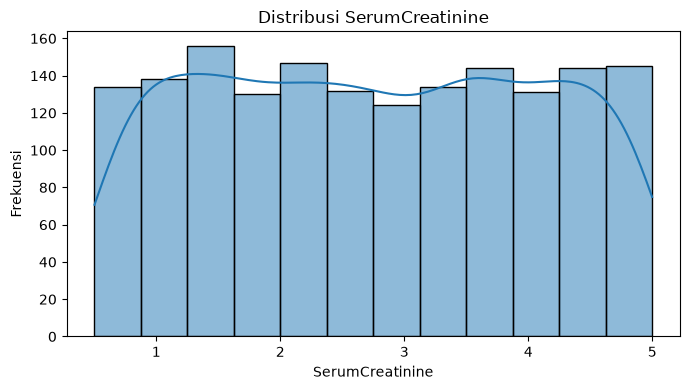

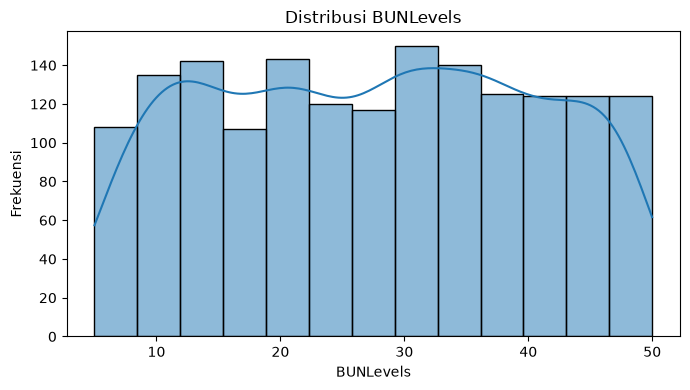

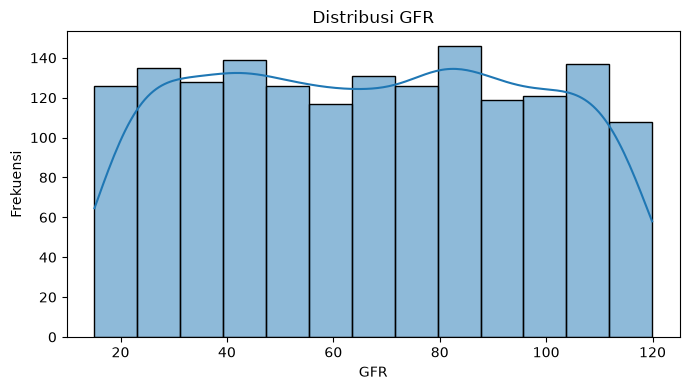

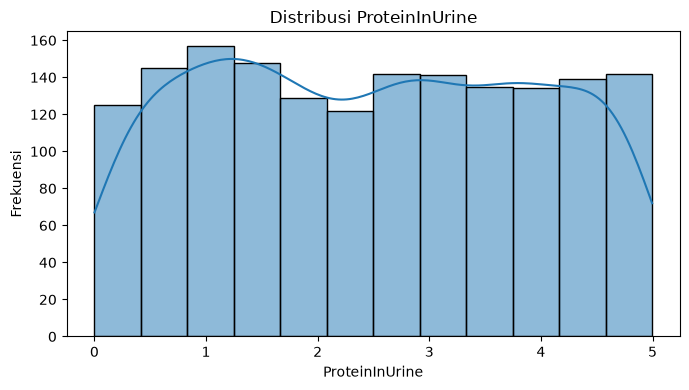

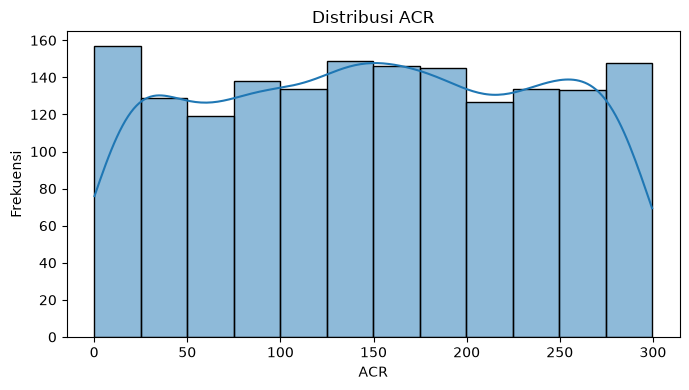

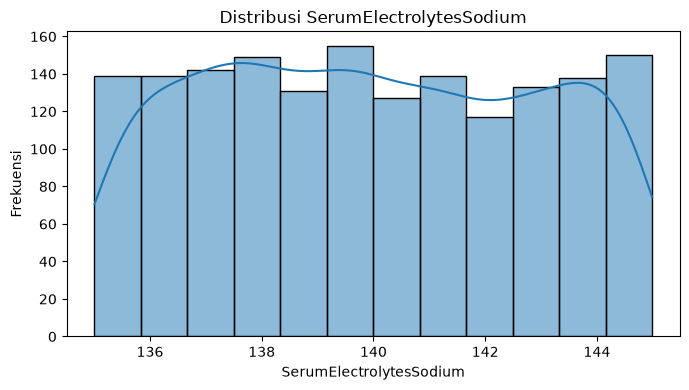

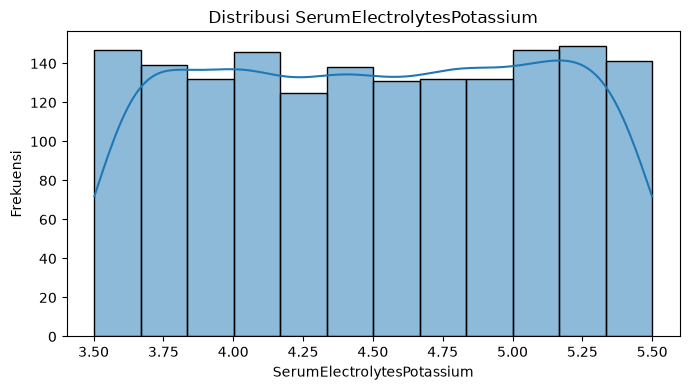

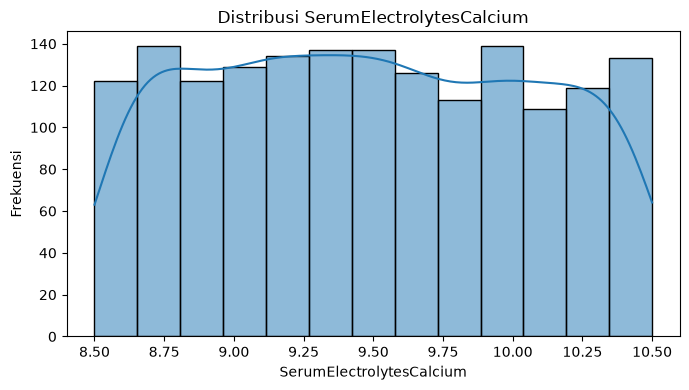

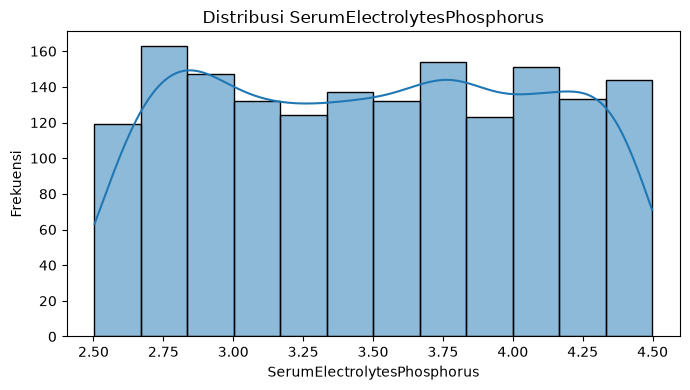

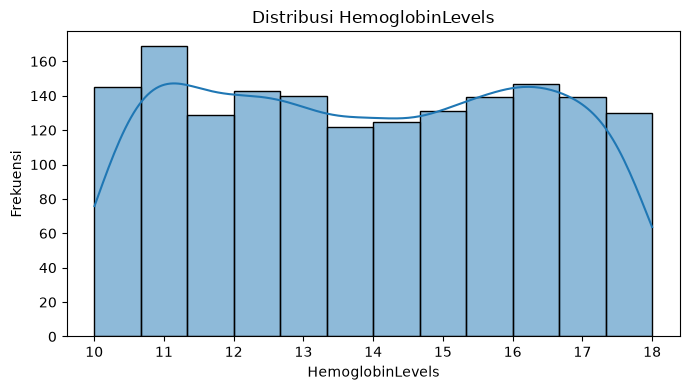

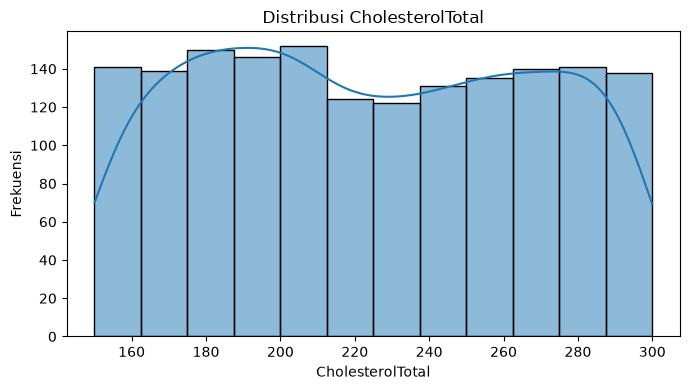

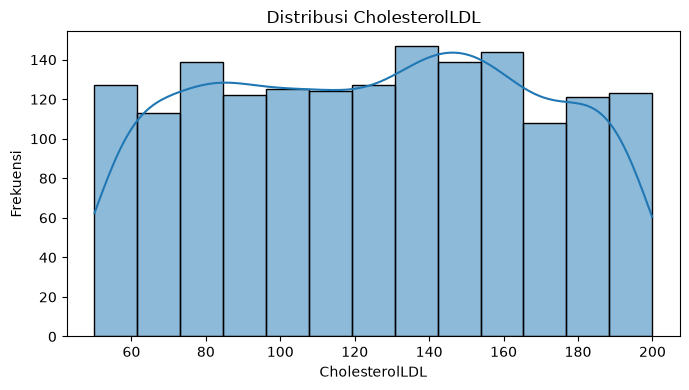

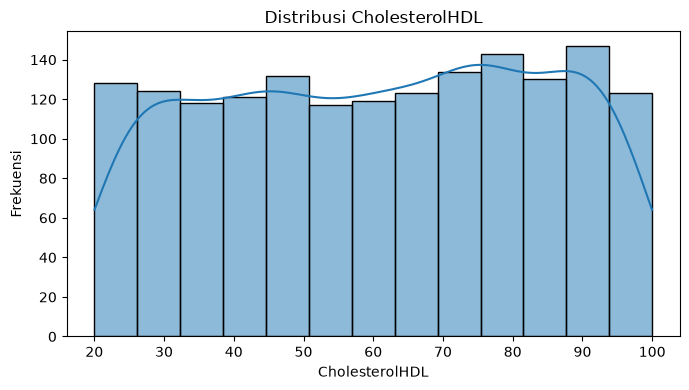

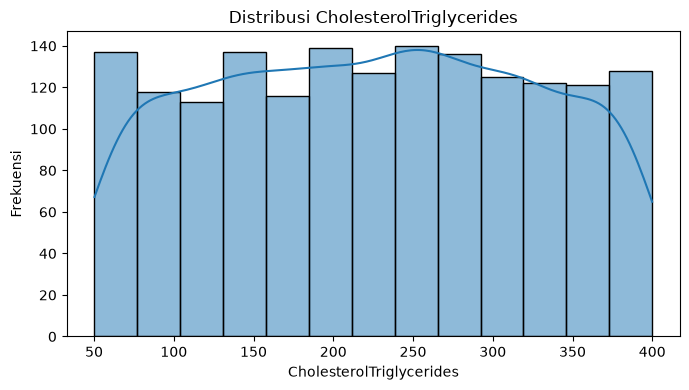

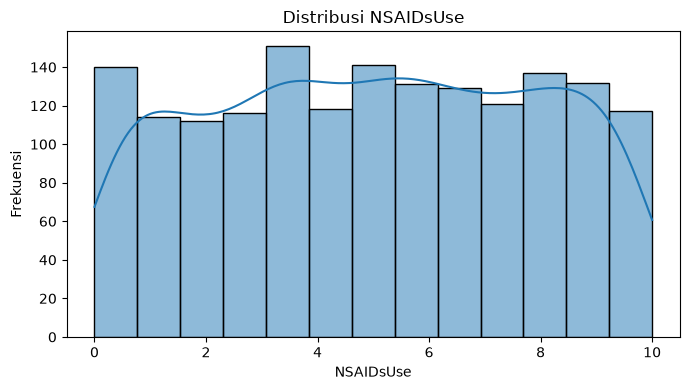

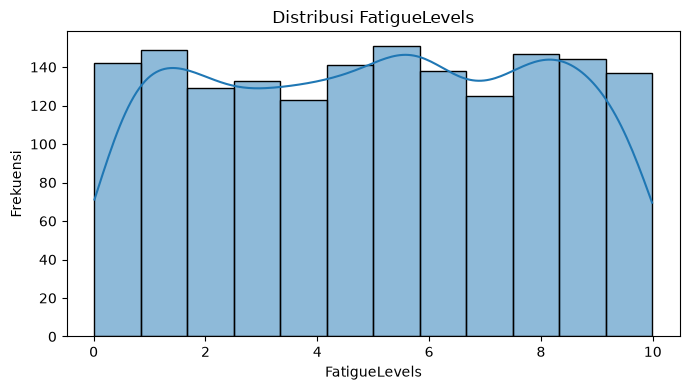

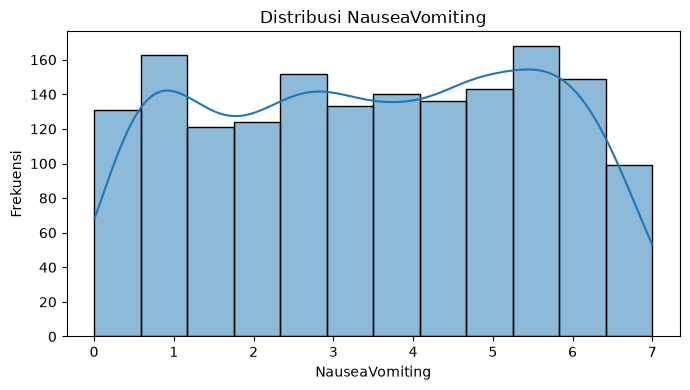

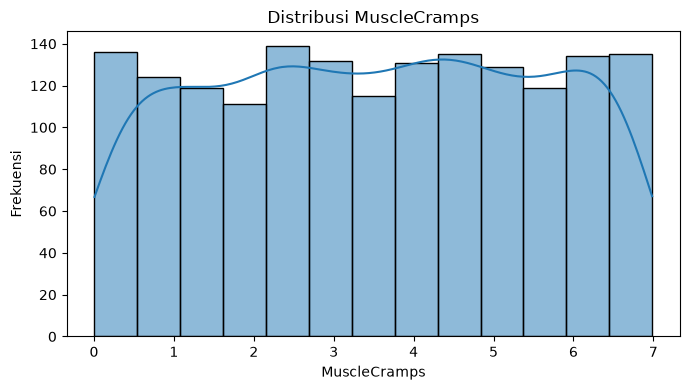

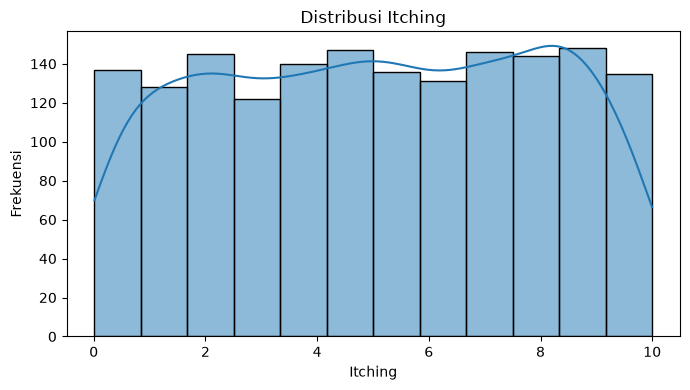

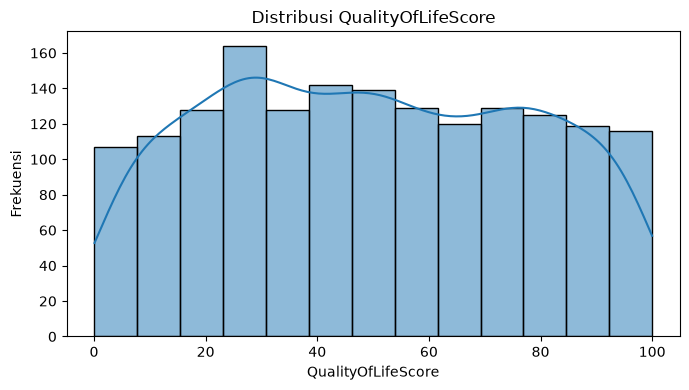

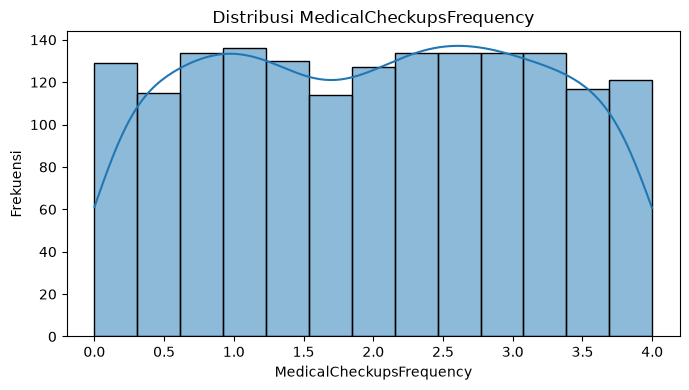

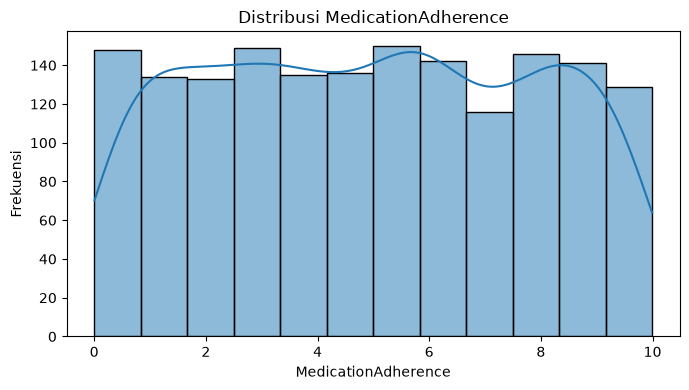

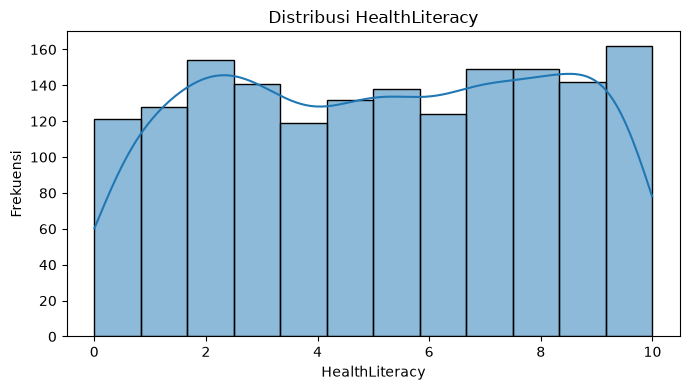

In [10]:
for col in continuous_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df_model,
        x=col,
        kde=True
    )

    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")

    plt.tight_layout()
    plt.show()

### 5.6 Distribusi Fitur Kategorikal

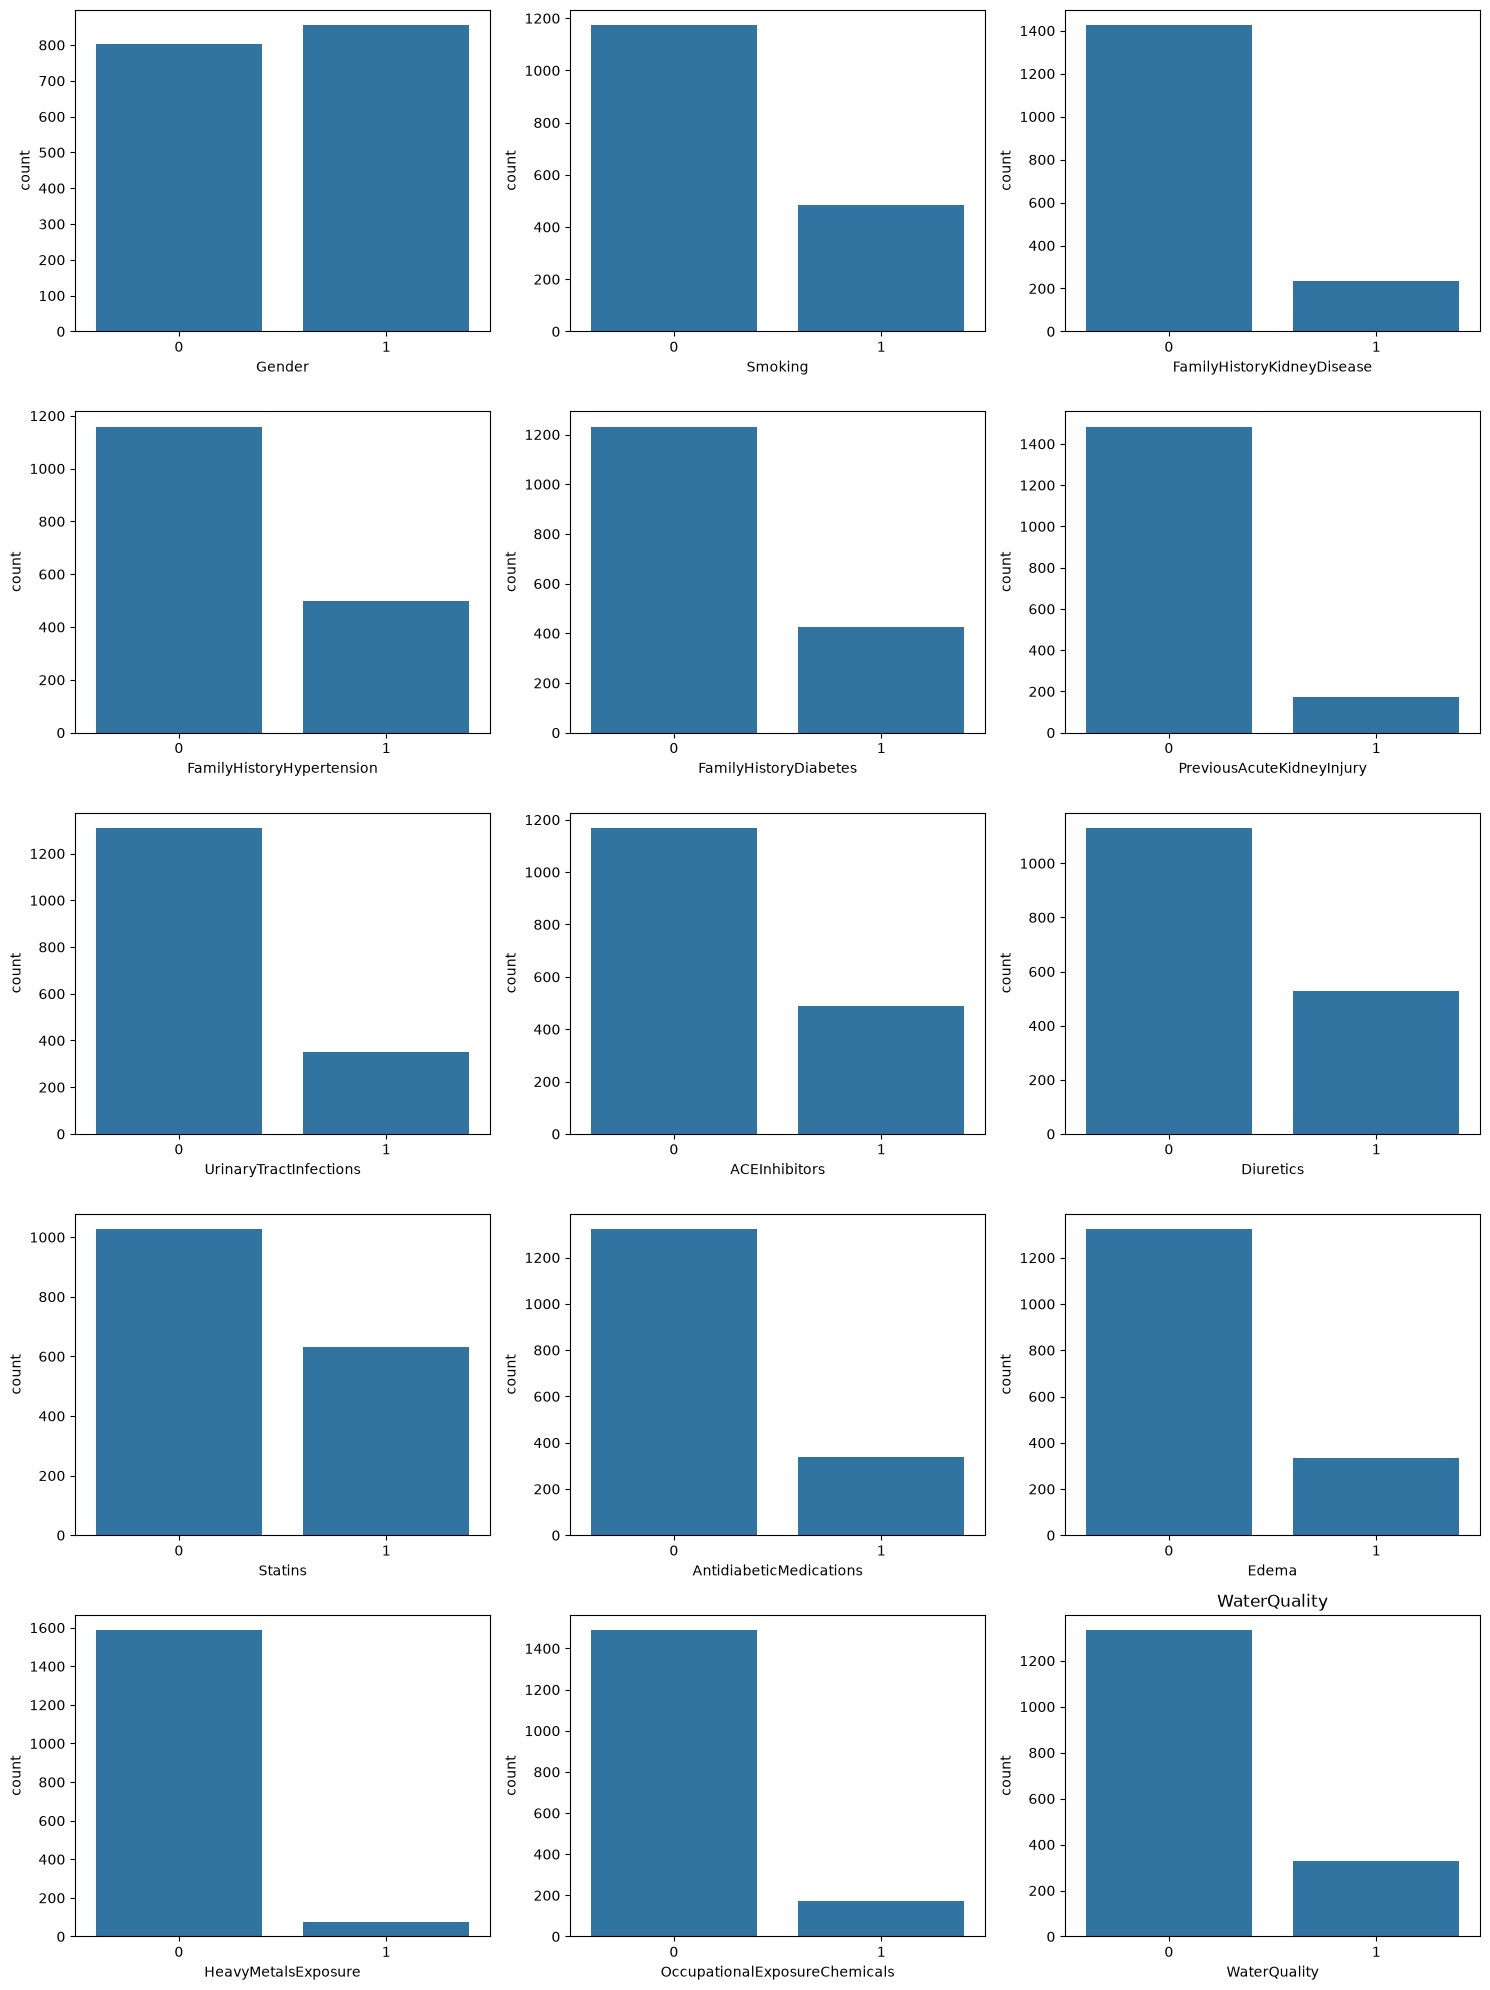

In [11]:
n_cols = 3
n_rows = math.ceil(len(binary_cols)/n_cols)

plt.figure(figsize=(15, n_rows*4))
for i, col in enumerate(binary_cols,1):
    plt.subplot(n_rows, n_cols, i)
    sns.countplot(
        x=df[col]
    )
plt.title(col)
plt.tight_layout()
plt.show()

### 5.7 Cek Outliers

#### 5.7.1 Scater plot

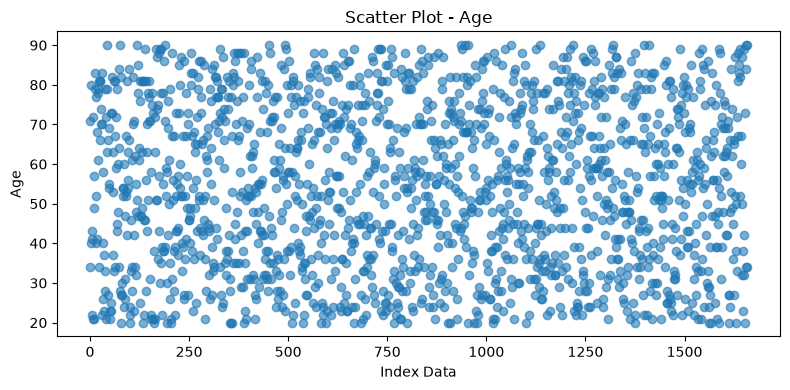

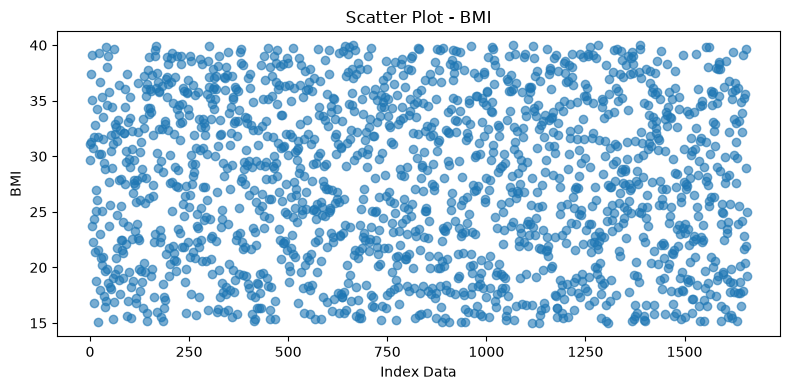

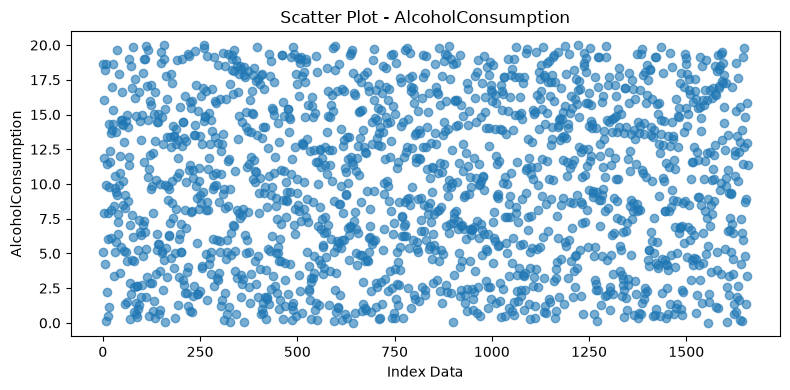

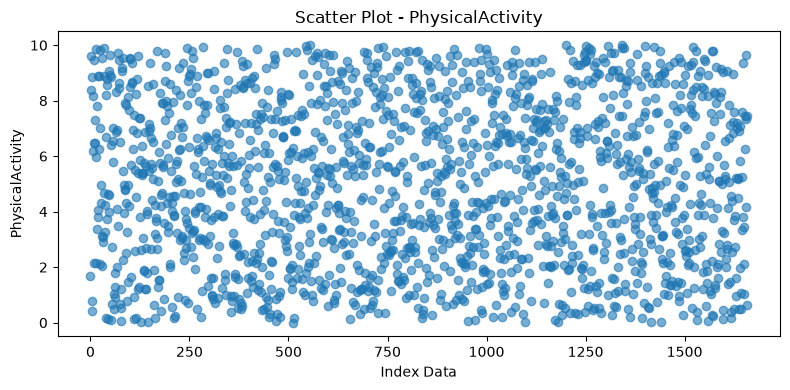

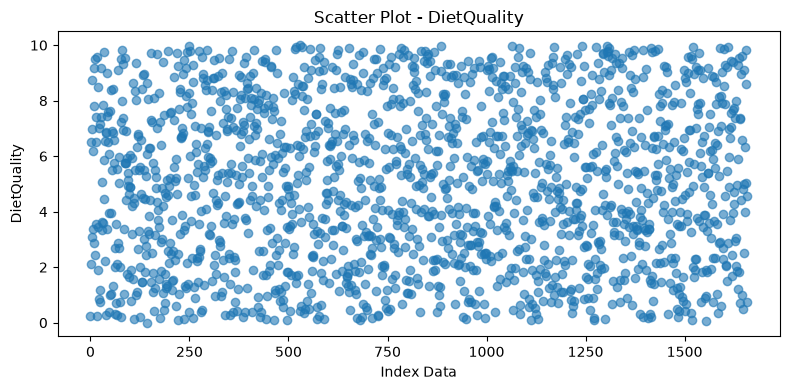

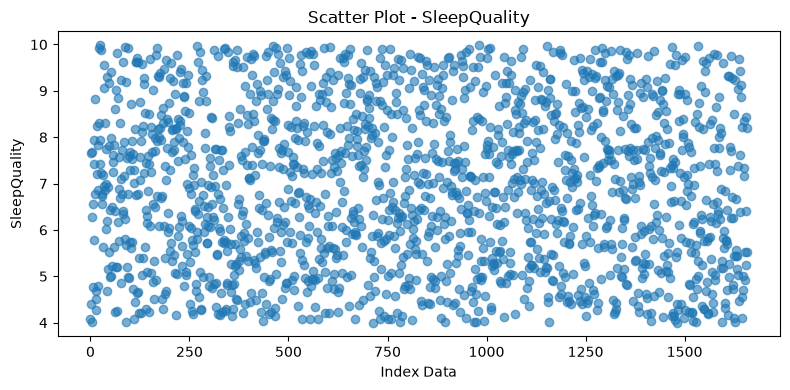

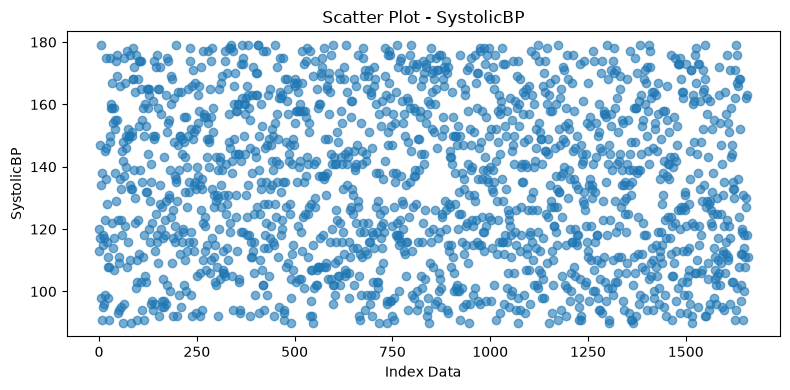

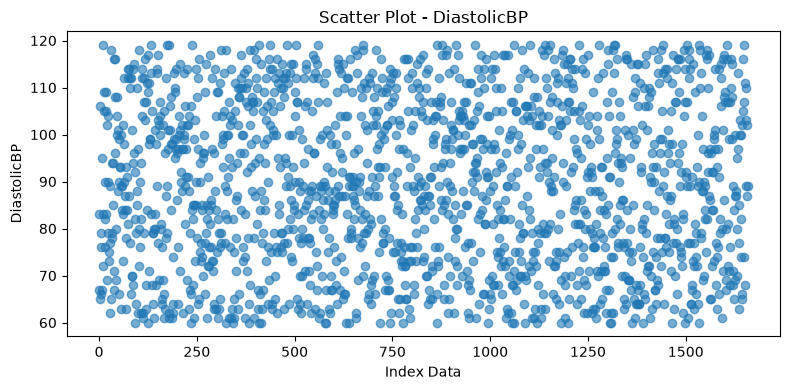

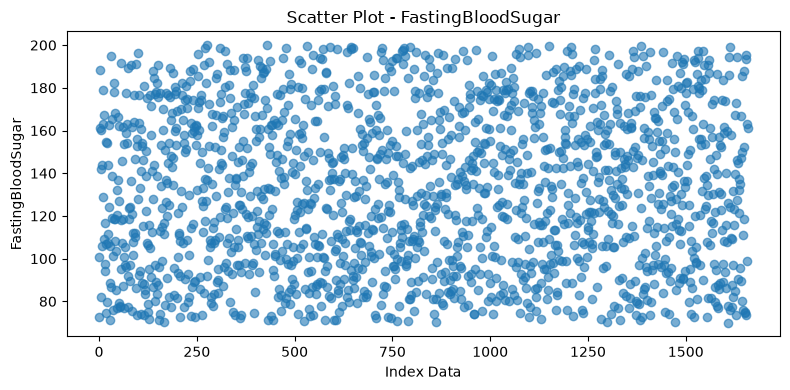

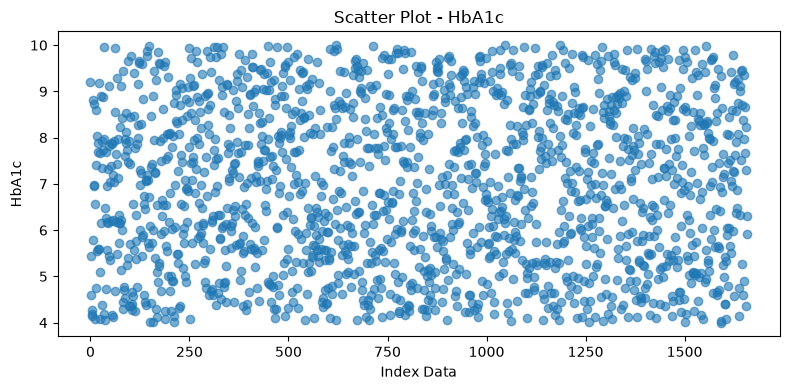

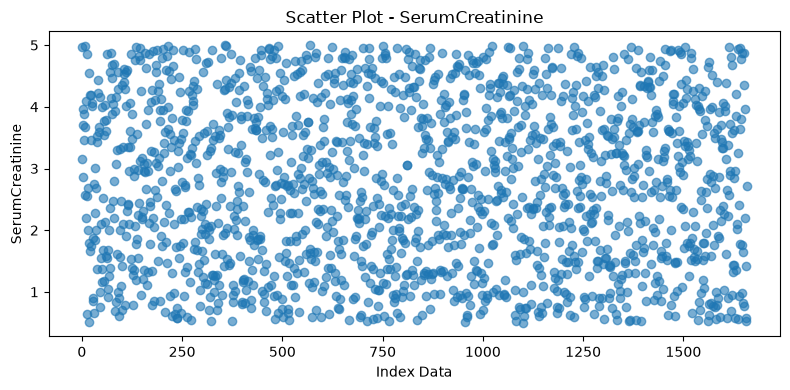

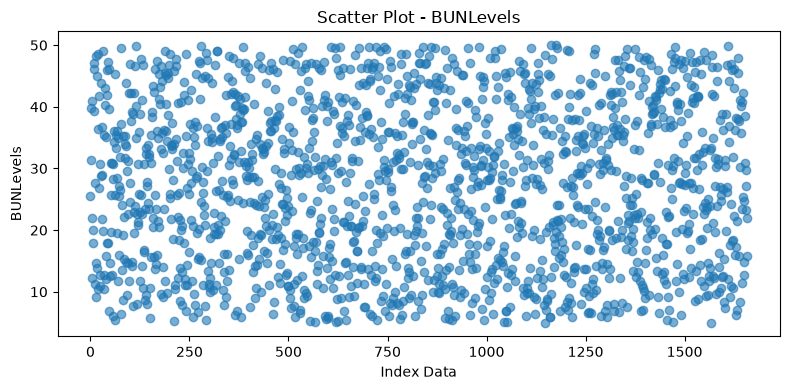

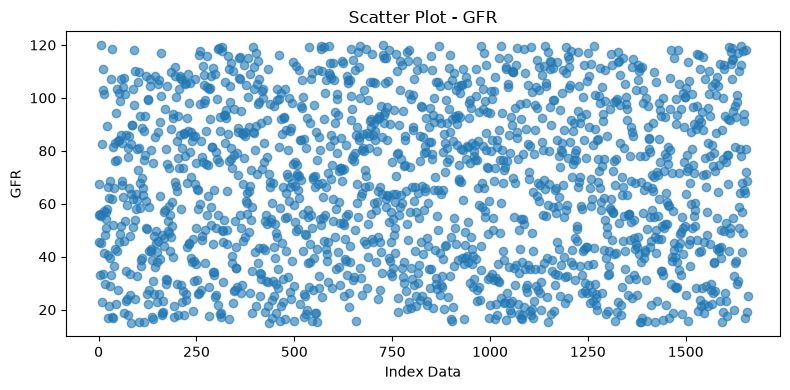

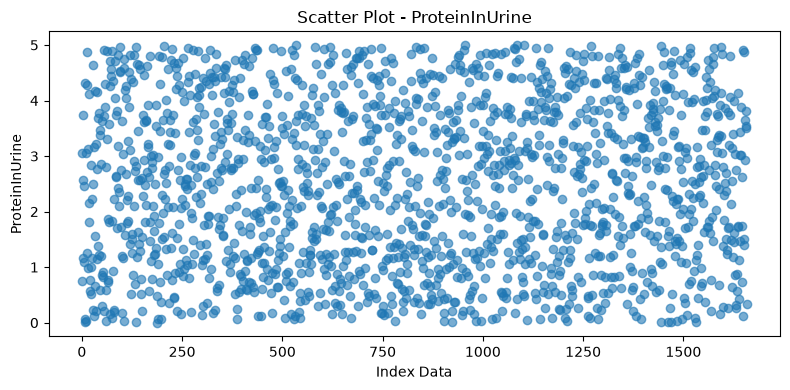

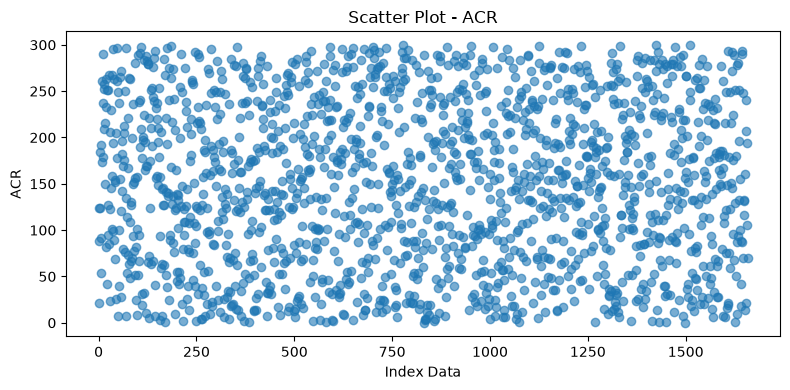

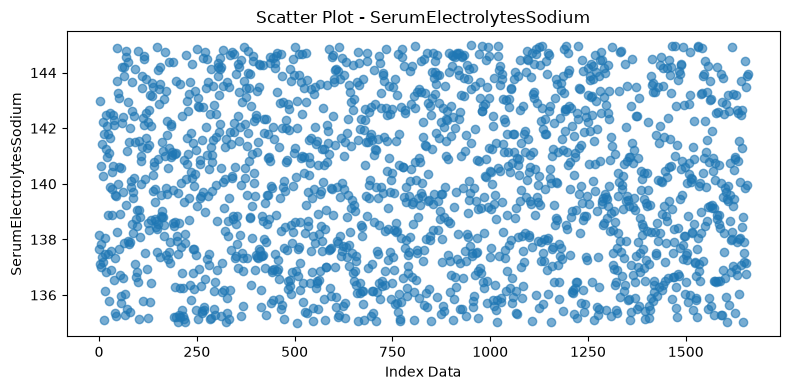

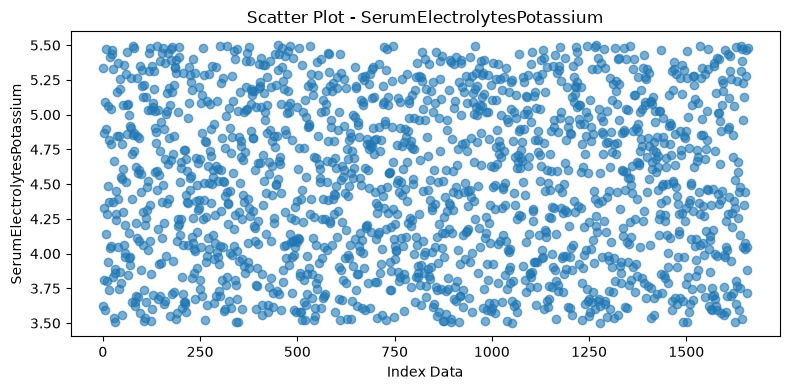

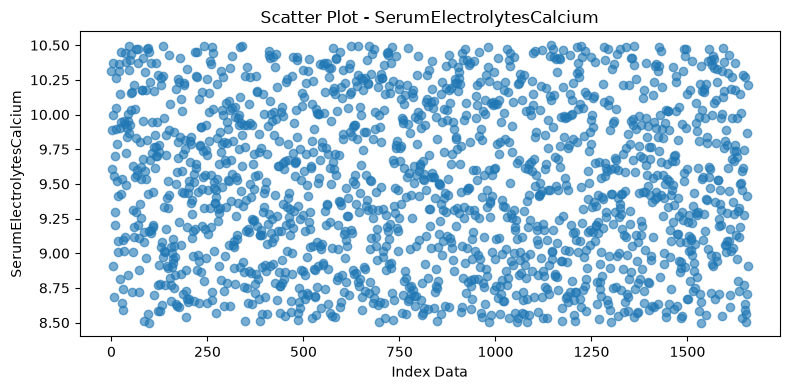

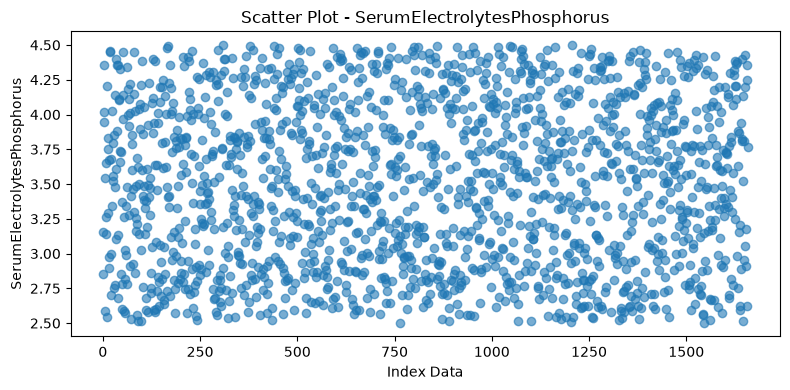

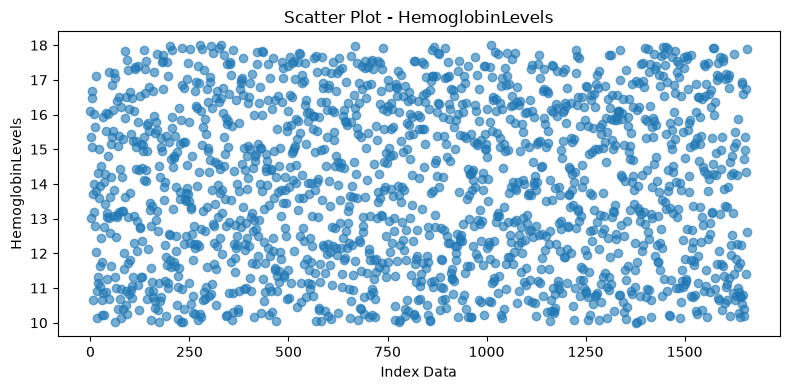

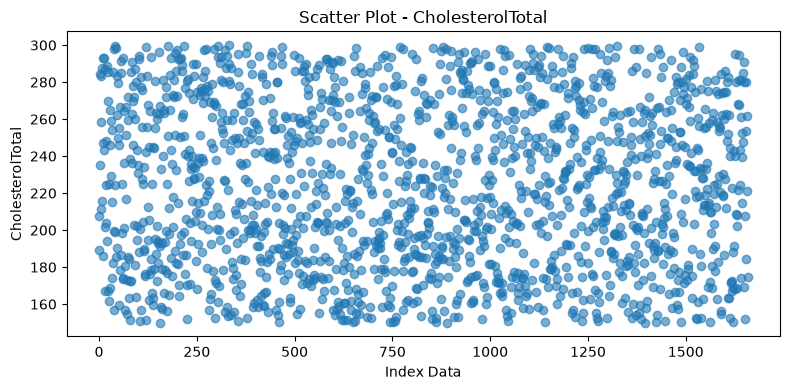

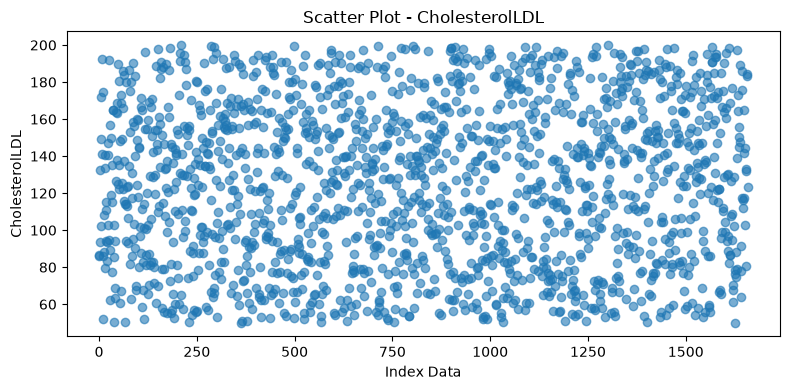

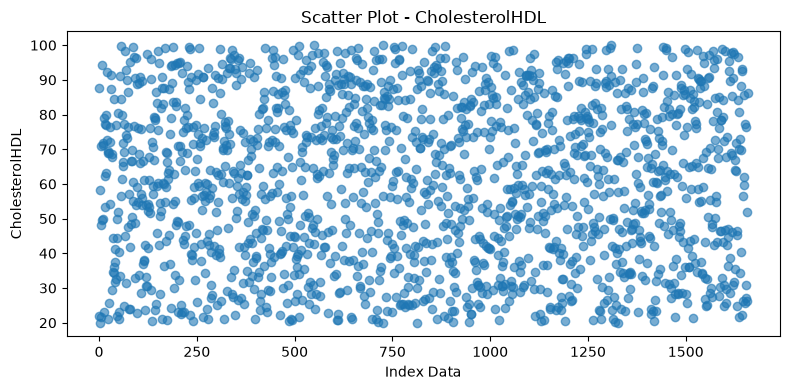

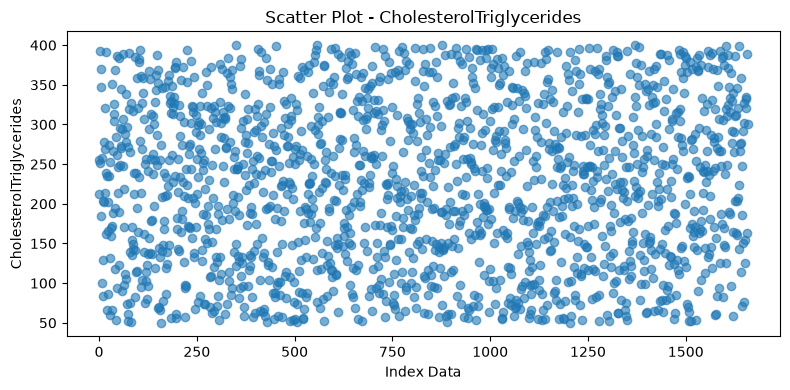

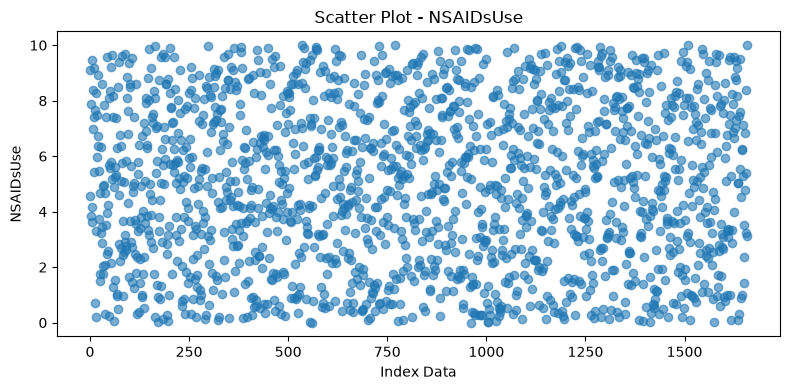

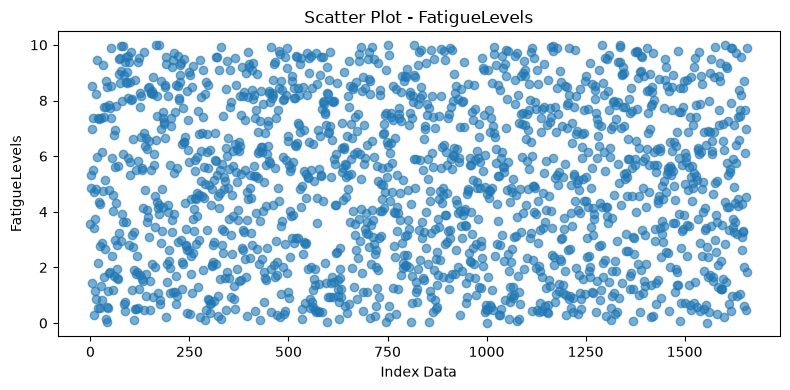

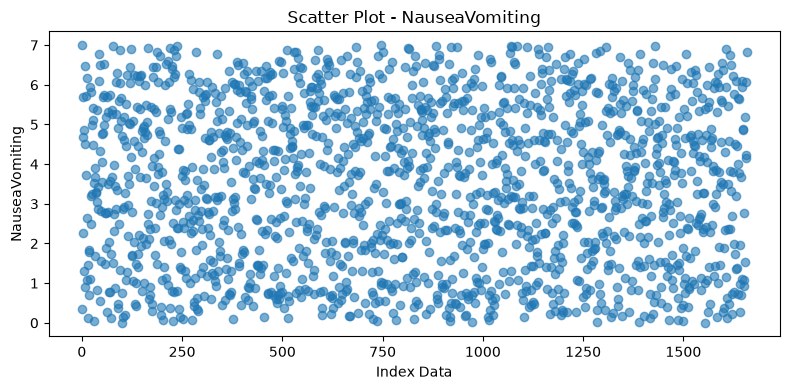

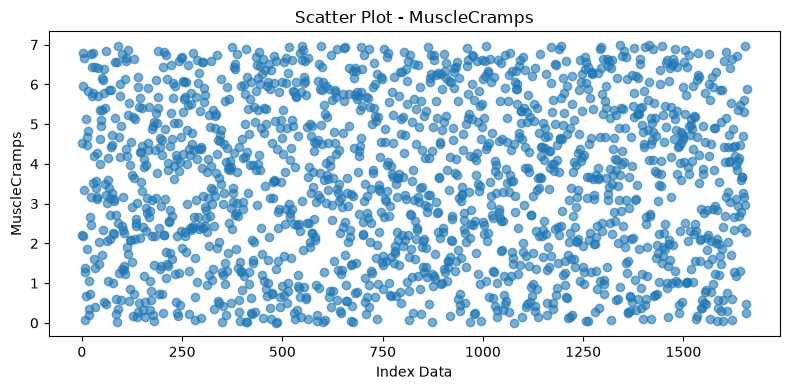

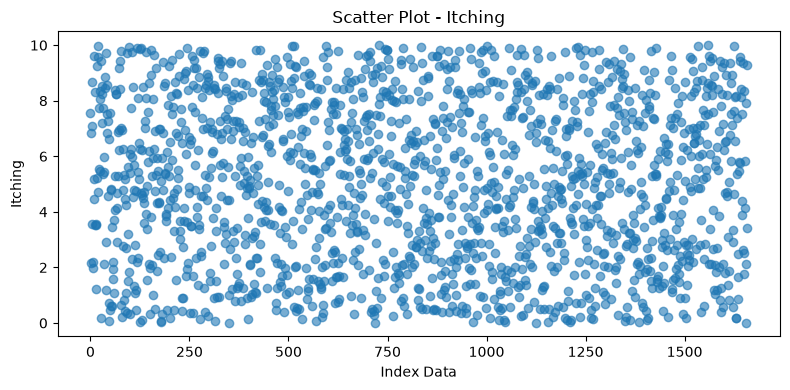

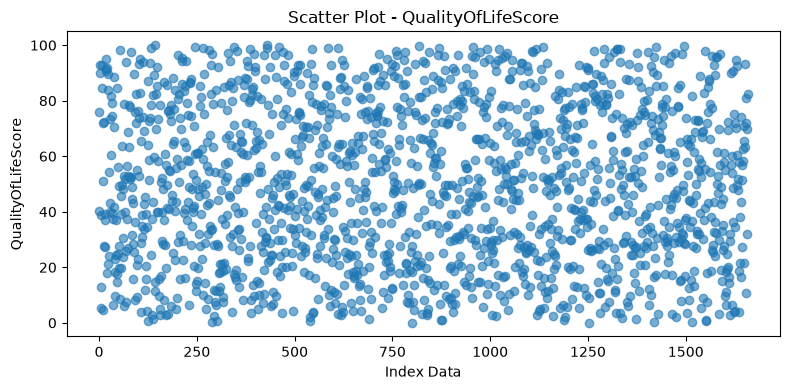

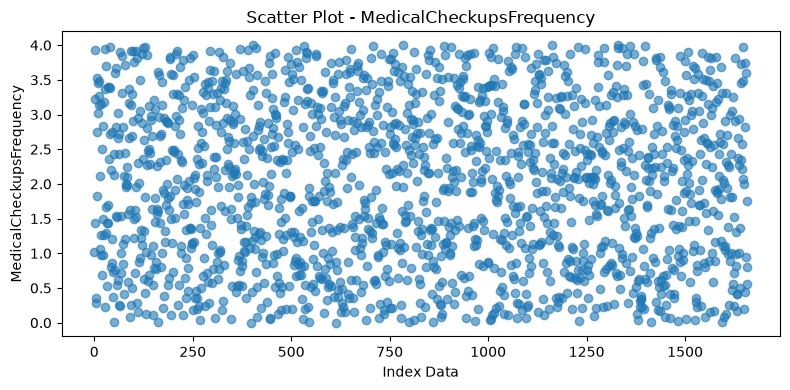

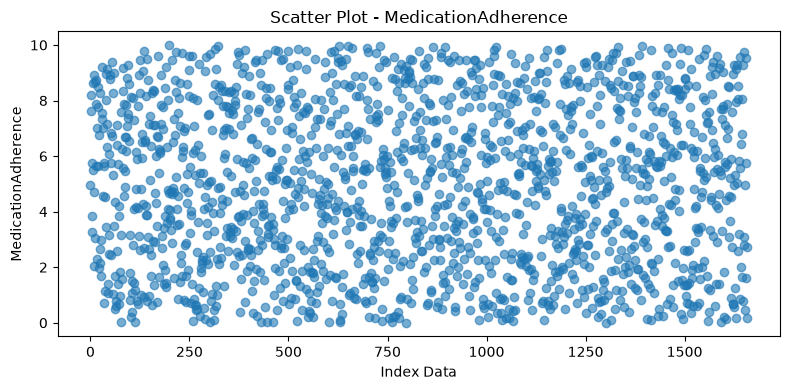

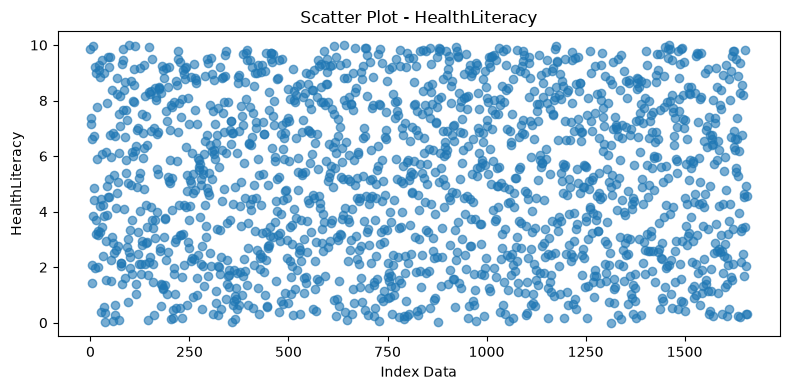

In [12]:
for col in continuous_cols:

    plt.figure(figsize=(8, 4))

    plt.scatter(
        range(len(df_model)),
        df_model[col],
        alpha=0.6
    )

    plt.title(f'Scatter Plot - {col}')
    plt.xlabel('Index Data')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

#### 5.7.2 IQR

In [13]:
outlier_summary = []

for col in continuous_cols:

    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_model[col] < lower_bound) |
        (df_model[col] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier Percentage': (
            outlier_count / len(df_model) * 100
        )
    })


outlier_summary = pd.DataFrame(
    outlier_summary
)

display(
    outlier_summary
    .sort_values(
        by='Outlier Count',
        ascending=False
    )
    .round(3)
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,36.000,72.000,36.000,-18.000,126.000,0,0.0
1,BMI,21.471,34.016,12.544,2.655,52.832,0,0.0
2,AlcoholConsumption,5.051,14.967,9.916,-9.823,29.841,0,0.0
3,PhysicalActivity,2.555,7.461,4.906,-4.803,14.819,0,0.0
4,DietQuality,2.558,7.428,4.870,-4.746,14.733,0,0.0
5,SleepQuality,5.487,8.346,2.859,1.198,12.635,0,0.0
6,SystolicBP,113.000,157.000,44.000,47.000,223.000,0,0.0
7,DiastolicBP,75.000,104.000,29.000,31.500,147.500,0,0.0
8,FastingBloodSugar,100.505,163.108,62.604,6.599,257.014,0,0.0
9,HbA1c,5.495,8.524,3.029,0.952,13.066,0,0.0


## 6. Prepocessing

### 6.1 Pisahkan Fitur & Target

In [14]:
X = df_model.drop(
    columns=['Diagnosis']
)

y = df_model['Diagnosis']

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts())

Ukuran X: (1659, 51)
Ukuran y: (1659,)

Distribusi target:
Diagnosis
1    1524
0     135
Name: count, dtype: int64


### 6.2 Train Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("===== HASIL TRAIN-TEST SPLIT =====")

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("\nDistribusi y_train:")
print(y_train.value_counts().sort_index())

print("\nDistribusi y_test:")
print(y_test.value_counts().sort_index())

===== HASIL TRAIN-TEST SPLIT =====
X_train : (1327, 51)
X_test  : (332, 51)
y_train : (1327,)
y_test  : (332,)

Distribusi y_train:
Diagnosis
0     108
1    1219
Name: count, dtype: int64

Distribusi y_test:
Diagnosis
0     27
1    305
Name: count, dtype: int64


## 7. Feature Selection — RFECV


In [16]:
from sklearn.feature_selection import RFECV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

rf_selector = RandomForestClassifier(
    criterion='gini',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

cv_rfecv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rfecv = RFECV(
    estimator=rf_selector,
    step=1,
    min_features_to_select=1,
    cv=cv_rfecv,
    scoring='balanced_accuracy',
    importance_getter='feature_importances_',
    n_jobs=-1
)

rfecv.fit(
    X_train,
    y_train
)

selected_features = X_train.columns[
    rfecv.support_
].tolist()

print("======================================================")
print("             HASIL RFECV")
print("======================================================")
print(f"Jumlah fitur awal     : {X_train.shape[1]}")
print(f"Jumlah fitur terpilih : {len(selected_features)}")
print(
    f"Best CV Balanced Accuracy : "
    f"{rfecv.cv_results_['mean_test_score'].max():.4f}"
)

print()
print("Selected Features:")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i:>2}. {feature}")

             HASIL RFECV
Jumlah fitur awal     : 51
Jumlah fitur terpilih : 4
Best CV Balanced Accuracy : 0.6948

Selected Features:
 1. SerumCreatinine
 2. GFR
 3. ProteinInUrine
 4. Itching


In [17]:
# ============================================================
# FEATURE IMPORTANCE RANDOM FOREST
# ============================================================

rf_importance = RandomForestClassifier(
    criterion='gini',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_importance.fit(
    X_train,
    y_train
)

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_importance.feature_importances_
})

importance_df = (
    importance_df
    .sort_values(
        by='Importance',
        ascending=False
    )
    .reset_index(drop=True)
)

importance_df['Rank'] = (
    importance_df.index + 1
)

display(
    importance_df.round(4)
)

,Feature,Importance,Rank
0,SerumCreatinine,0.1152,1
1,GFR,0.0774,2
2,Itching,0.0601,3
3,ProteinInUrine,0.0557,4
4,BUNLevels,0.0389,5
5,SystolicBP,0.0345,6
6,MuscleCramps,0.0336,7
7,FastingBloodSugar,0.0281,8
8,HbA1c,0.0273,9
9,AlcoholConsumption,0.0265,10


In [18]:
# ============================================================
# RFECV SCORE BERDASARKAN JUMLAH FITUR
# ============================================================

rfecv_score_table = pd.DataFrame({

    'Number of Features':
        rfecv.cv_results_['n_features'],

    'Mean CV Balanced Accuracy':
        rfecv.cv_results_['mean_test_score'],

    'Std CV Balanced Accuracy':
        rfecv.cv_results_['std_test_score']
})


rfecv_score_table = (
    rfecv_score_table
    .sort_values(
        'Number of Features'
    )
    .reset_index(drop=True)
)


display(
    rfecv_score_table.round(4)
)

,Number of Features,Mean CV Balanced Accuracy,Std CV Balanced Accuracy
0,1,0.5487,0.0316
1,2,0.6416,0.0288
2,3,0.6675,0.0212
3,4,0.6948,0.0430
4,5,0.6610,0.0475
5,6,0.6542,0.0308
6,7,0.6670,0.0401
7,8,0.6467,0.0256
8,9,0.6786,0.0385
9,10,0.6556,0.0324


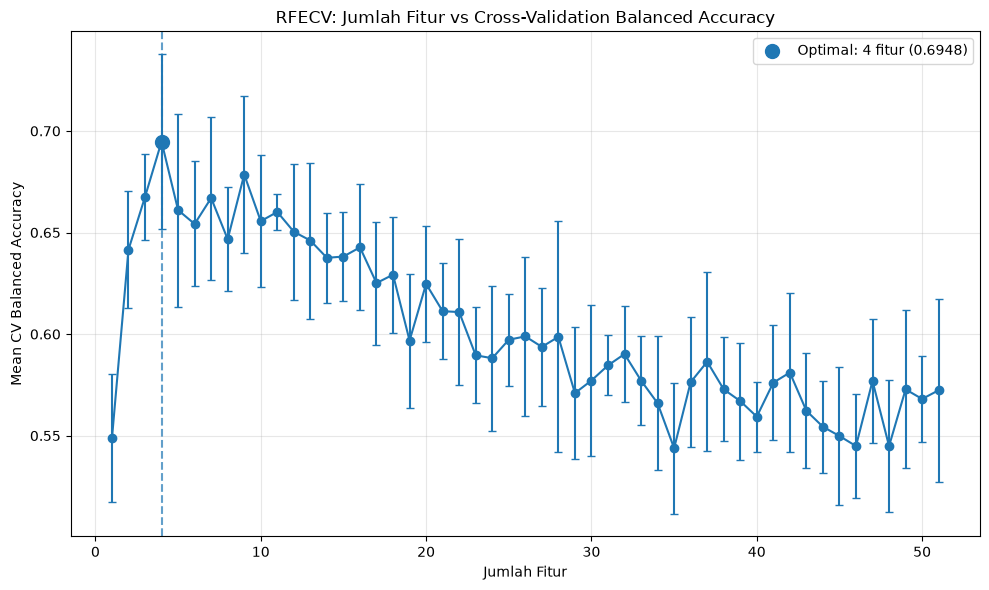

In [19]:
# ============================================================
# VISUALISASI HASIL RFECV
# ============================================================

plt.figure(figsize=(10, 6))

plt.errorbar(
    rfecv_score_table['Number of Features'],
    rfecv_score_table['Mean CV Balanced Accuracy'],
    yerr=rfecv_score_table['Std CV Balanced Accuracy'],
    marker='o',
    capsize=3,
    linewidth=1.5
)

# Jumlah fitur optimal
optimal_n_features = rfecv.n_features_

# Ambil skor optimal
optimal_score = (
    rfecv_score_table
    .loc[
        rfecv_score_table['Number of Features']
        == optimal_n_features,
        'Mean CV Balanced Accuracy'
    ]
    .iloc[0]
)

# Tandai titik optimal
plt.scatter(
    optimal_n_features,
    optimal_score,
    s=100,
    zorder=5,
    label=(
        f'Optimal: {optimal_n_features} fitur '
        f'({optimal_score:.4f})'
    )
)

plt.axvline(
    optimal_n_features,
    linestyle='--',
    alpha=0.7
)

plt.xlabel(
    'Jumlah Fitur'
)

plt.ylabel(
    'Mean CV Balanced Accuracy'
)

plt.title(
    'RFECV: Jumlah Fitur vs Cross-Validation Balanced Accuracy'
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [20]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print("======================================================")
print("                SELECTED FEATURES")
print("======================================================")
print(f"X_train shape : {X_train_selected.shape}")
print(f"X_test shape  : {X_test_selected.shape}")

print("\nFitur terpilih:")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i:>2}. {feature}")

                SELECTED FEATURES
X_train shape : (1327, 4)
X_test shape  : (332, 4)

Fitur terpilih:
 1. SerumCreatinine
 2. GFR
 3. ProteinInUrine
 4. Itching


## 8. Persiapan Optimasi Class Weight


In [21]:
# ============================================================
# PERSIAPAN OPTIMASI CLASS WEIGHT
# ============================================================

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# Cross Validation
# ------------------------------------------------------------

cv_class_weight = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# Random Forest dasar
# ------------------------------------------------------------

rf_class_weight_base = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Bobot untuk kelas Non-CKD
# ------------------------------------------------------------

class_weight_values = [
    1.0,
    2.0,
    3.0,
    4.0,
    5.0,
    8.0,
    11.0
]


print("======================================================")
print("        OPTIMASI CLASS WEIGHT")
print("======================================================")

print("Cross Validation : Stratified 5-Fold")
print("Random Forest    : 100 trees")
print("Criterion        : Gini")

print("\nBobot Non-CKD yang akan diuji:")
print(class_weight_values)

print("\nBobot CKD:")
print("1.0")

        OPTIMASI CLASS WEIGHT
Cross Validation : Stratified 5-Fold
Random Forest    : 100 trees
Criterion        : Gini

Bobot Non-CKD yang akan diuji:
[1.0, 2.0, 3.0, 4.0, 5.0, 8.0, 11.0]

Bobot CKD:
1.0


## 9. Eksperimen Berbagai Bobot Class Weight

In [22]:
# ============================================================
# EKSPERIMEN BERBAGAI CLASS WEIGHT
# ============================================================

class_weight_results = []


for minority_weight in class_weight_values:

    fold_metrics = {
        'accuracy': [],
        'balanced_accuracy': [],
        'precision_macro': [],
        'recall_macro': [],
        'f1_macro': [],
        'precision_non_ckd': [],
        'recall_non_ckd': [],
        'f1_non_ckd': [],
        'roc_auc': [],
        'pr_auc_ckd': [],
        'pr_auc_non_ckd': []
    }


    for train_idx, valid_idx in cv_class_weight.split(
        X_train_selected,
        y_train
    ):

        # ----------------------------------------------------
        # Split training dan validation fold
        # ----------------------------------------------------

        X_tr = X_train_selected.iloc[train_idx]
        X_val = X_train_selected.iloc[valid_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[valid_idx]


        # ----------------------------------------------------
        # Class Weight
        # ----------------------------------------------------

        class_weight = {
            0: minority_weight,
            1: 1.0
        }


        # ----------------------------------------------------
        # Model
        # ----------------------------------------------------

        model = clone(
            rf_class_weight_base
        )

        model.set_params(
            class_weight=class_weight
        )


        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        model.fit(
            X_tr,
            y_tr
        )


        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        y_pred = model.predict(
            X_val
        )

        y_prob_ckd = model.predict_proba(
            X_val
        )[:, 1]

        y_prob_non_ckd = (
            1 - y_prob_ckd
        )

        y_val_non_ckd = (
            y_val == 0
        ).astype(int)


        # ----------------------------------------------------
        # Overall Metrics
        # ----------------------------------------------------

        fold_metrics['accuracy'].append(
            accuracy_score(
                y_val,
                y_pred
            )
        )

        fold_metrics['balanced_accuracy'].append(
            balanced_accuracy_score(
                y_val,
                y_pred
            )
        )

        fold_metrics['precision_macro'].append(
            precision_score(
                y_val,
                y_pred,
                average='macro',
                zero_division=0
            )
        )

        fold_metrics['recall_macro'].append(
            recall_score(
                y_val,
                y_pred,
                average='macro',
                zero_division=0
            )
        )

        fold_metrics['f1_macro'].append(
            f1_score(
                y_val,
                y_pred,
                average='macro',
                zero_division=0
            )
        )


        # ----------------------------------------------------
        # Non-CKD Metrics
        # ----------------------------------------------------

        fold_metrics['precision_non_ckd'].append(
            precision_score(
                y_val,
                y_pred,
                pos_label=0,
                zero_division=0
            )
        )

        fold_metrics['recall_non_ckd'].append(
            recall_score(
                y_val,
                y_pred,
                pos_label=0,
                zero_division=0
            )
        )

        fold_metrics['f1_non_ckd'].append(
            f1_score(
                y_val,
                y_pred,
                pos_label=0,
                zero_division=0
            )
        )


        # ----------------------------------------------------
        # Probability-based Metrics
        # ----------------------------------------------------

        fold_metrics['roc_auc'].append(
            roc_auc_score(
                y_val,
                y_prob_ckd
            )
        )

        fold_metrics['pr_auc_ckd'].append(
            average_precision_score(
                y_val,
                y_prob_ckd
            )
        )

        fold_metrics['pr_auc_non_ckd'].append(
            average_precision_score(
                y_val_non_ckd,
                y_prob_non_ckd
            )
        )


    # --------------------------------------------------------
    # Rata-rata 5 Fold
    # --------------------------------------------------------

    class_weight_results.append({

        'Class Weight': minority_weight,

        'Accuracy': np.mean(
            fold_metrics['accuracy']
        ),

        'Balanced Accuracy': np.mean(
            fold_metrics['balanced_accuracy']
        ),

        'Precision Macro': np.mean(
            fold_metrics['precision_macro']
        ),

        'Recall Macro': np.mean(
            fold_metrics['recall_macro']
        ),

        'F1 Macro': np.mean(
            fold_metrics['f1_macro']
        ),

        'Precision Non-CKD': np.mean(
            fold_metrics['precision_non_ckd']
        ),

        'Recall Non-CKD': np.mean(
            fold_metrics['recall_non_ckd']
        ),

        'F1 Non-CKD': np.mean(
            fold_metrics['f1_non_ckd']
        ),

        'ROC-AUC': np.mean(
            fold_metrics['roc_auc']
        ),

        'PR-AUC CKD': np.mean(
            fold_metrics['pr_auc_ckd']
        ),

        'PR-AUC Non-CKD': np.mean(
            fold_metrics['pr_auc_non_ckd']
        )
    })


class_weight_comparison = pd.DataFrame(
    class_weight_results
)


display(
    class_weight_comparison.round(4)
)

,Class Weight,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Non-CKD,Recall Non-CKD,F1 Non-CKD,ROC-AUC,PR-AUC CKD,PR-AUC Non-CKD
0,1.0,0.9216,0.6109,0.7606,0.6109,0.6435,0.5853,0.2398,0.3287,0.7984,0.9712,0.3836
1,2.0,0.9156,0.6459,0.7277,0.6459,0.6701,0.5136,0.3238,0.3856,0.7855,0.9668,0.3772
2,3.0,0.9103,0.6635,0.6959,0.6635,0.6757,0.4467,0.3688,0.3998,0.7798,0.9658,0.3782
3,4.0,0.9111,0.6726,0.6980,0.6726,0.6826,0.4494,0.3879,0.4134,0.7807,0.9656,0.3594
4,5.0,0.9088,0.6712,0.6906,0.6712,0.6791,0.4348,0.3874,0.4077,0.7816,0.9667,0.3561
5,8.0,0.9096,0.6842,0.6929,0.6842,0.6880,0.4372,0.4152,0.4252,0.7868,0.9673,0.3616
6,11.0,0.9096,0.6844,0.6949,0.6844,0.6889,0.4412,0.4156,0.4269,0.7775,0.9637,0.3635


## 10. Perbandingan Bobot

Bobot tidak dipilih hanya berdasarkan satu metrik.

Metrik utama yang diperhatikan:

1. **Balanced Accuracy**
2. **F1 Non-CKD**
3. **Recall Non-CKD**
4. **Precision Non-CKD**
5. **PR-AUC Non-CKD**

Metrik pendukung:

- F1 Macro
- ROC-AUC
- Accuracy

Tujuannya adalah mencari bobot yang memberikan **trade-off terbaik** antara kemampuan mendeteksi Non-CKD dan performa keseluruhan model.


In [23]:
# ============================================================
# RANKING CLASS WEIGHT
# ============================================================

class_weight_ranking_metrics = [
    'Balanced Accuracy',
    'F1 Non-CKD',
    'Recall Non-CKD',
    'Precision Non-CKD',
    'PR-AUC Non-CKD',
    'F1 Macro',
    'ROC-AUC'
]


class_weight_ranking = class_weight_comparison[
    ['Class Weight'] +
    class_weight_ranking_metrics
].copy()


for metric in class_weight_ranking_metrics:

    class_weight_ranking[
        f'Rank {metric}'
    ] = (
        class_weight_ranking[metric]
        .rank(
            method='min',
            ascending=False
        )
        .astype(int)
    )


rank_columns = [
    f'Rank {metric}'
    for metric in class_weight_ranking_metrics
]


class_weight_ranking[
    'Average Rank'
] = (
    class_weight_ranking[
        rank_columns
    ].mean(axis=1)
)


class_weight_ranking = (
    class_weight_ranking
    .sort_values(
        by='Average Rank'
    )
    .reset_index(drop=True)
)


display(
    class_weight_ranking.round(4)
)

,Class Weight,Balanced Accuracy,F1 Non-CKD,Recall Non-CKD,Precision Non-CKD,PR-AUC Non-CKD,F1 Macro,ROC-AUC,Rank Balanced Accuracy,Rank F1 Non-CKD,Rank Recall Non-CKD,Rank Precision Non-CKD,Rank PR-AUC Non-CKD,Rank F1 Macro,Rank ROC-AUC,Average Rank
0,11.0,0.6844,0.4269,0.4156,0.4412,0.3635,0.6889,0.7775,1,1,1,5,4,1,7,2.8571
1,8.0,0.6842,0.4252,0.4152,0.4372,0.3616,0.6880,0.7868,2,2,2,6,5,2,2,3.0000
2,4.0,0.6726,0.4134,0.3879,0.4494,0.3594,0.6826,0.7807,3,3,3,3,6,3,5,3.7143
3,1.0,0.6109,0.3287,0.2398,0.5853,0.3836,0.6435,0.7984,7,7,7,1,1,7,1,4.4286
4,3.0,0.6635,0.3998,0.3688,0.4467,0.3782,0.6757,0.7798,5,5,5,4,2,5,6,4.5714
5,2.0,0.6459,0.3856,0.3238,0.5136,0.3772,0.6701,0.7855,6,6,6,2,3,6,3,4.5714
6,5.0,0.6712,0.4077,0.3874,0.4348,0.3561,0.6791,0.7816,4,4,4,7,7,4,4,4.8571


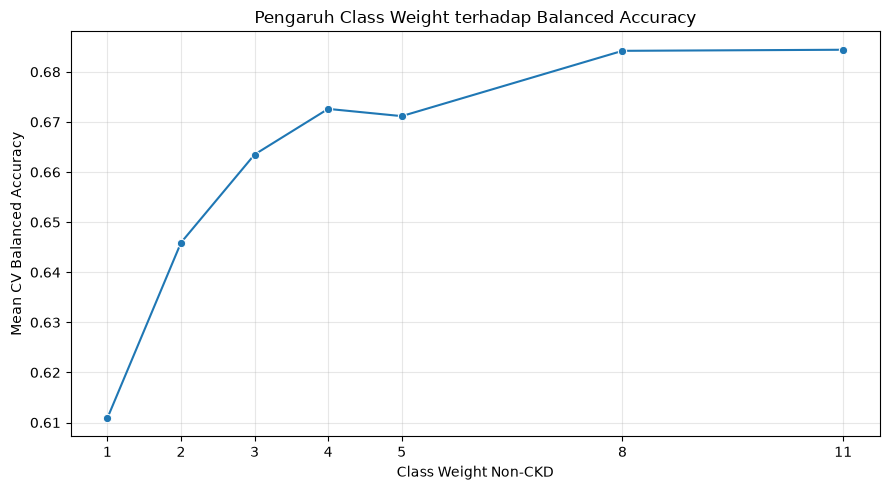

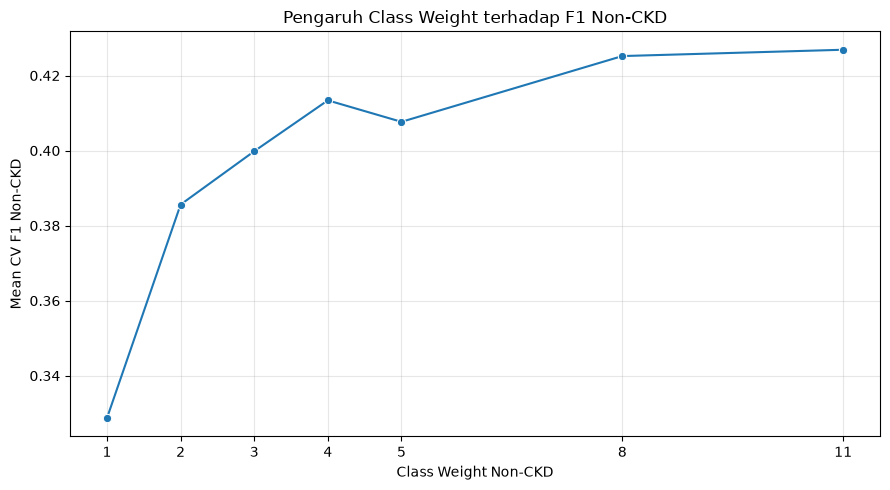

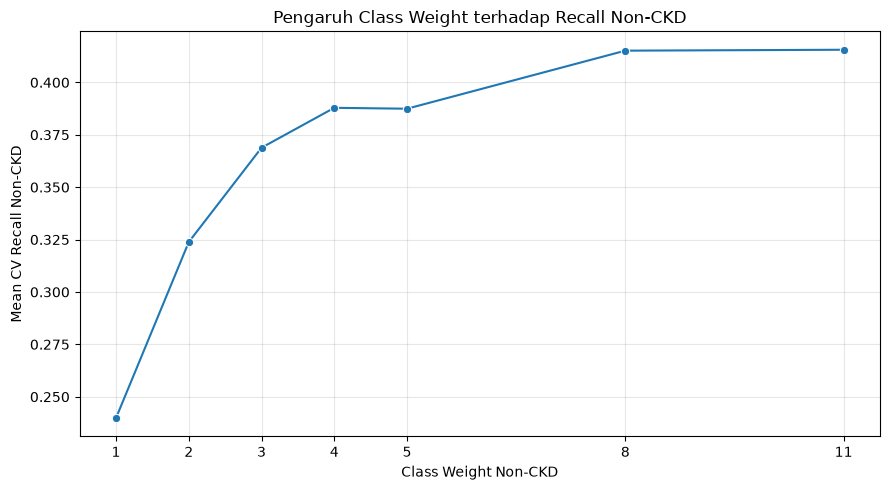

In [24]:
# ============================================================
# GRAFIK OPTIMASI CLASS WEIGHT
# ============================================================

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=class_weight_comparison,
    x='Class Weight',
    y='Balanced Accuracy',
    marker='o'
)

plt.xlabel(
    'Class Weight Non-CKD'
)

plt.ylabel(
    'Mean CV Balanced Accuracy'
)

plt.title(
    'Pengaruh Class Weight terhadap Balanced Accuracy'
)

plt.xticks(
    class_weight_values
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

sns.lineplot(
    data=class_weight_comparison,
    x='Class Weight',
    y='F1 Non-CKD',
    marker='o'
)

plt.xlabel(
    'Class Weight Non-CKD'
)

plt.ylabel(
    'Mean CV F1 Non-CKD'
)

plt.title(
    'Pengaruh Class Weight terhadap F1 Non-CKD'
)

plt.xticks(
    class_weight_values
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

sns.lineplot(
    data=class_weight_comparison,
    x='Class Weight',
    y='Recall Non-CKD',
    marker='o'
)

plt.xlabel(
    'Class Weight Non-CKD'
)

plt.ylabel(
    'Mean CV Recall Non-CKD'
)

plt.title(
    'Pengaruh Class Weight terhadap Recall Non-CKD'
)

plt.xticks(
    class_weight_values
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

## 11. Menentukan Class Weight Optimal

Class Weight optimal ditentukan berdasarkan hasil
Stratified 5-Fold Cross-Validation.

Pemilihan tidak hanya berdasarkan Balanced Accuracy,
tetapi mempertimbangkan trade-off antar metrik, terutama:

- Balanced Accuracy
- F1 Non-CKD
- Recall Non-CKD
- Precision Non-CKD
- PR-AUC Non-CKD
- F1 Macro
- ROC-AUC

Test set tidak digunakan dalam proses pemilihan
Class Weight optimal.

In [25]:
# ============================================================
# PENENTUAN CLASS WEIGHT OPTIMAL
# ============================================================

best_class_weight = (
    class_weight_ranking
    .iloc[0]
)


print("======================================================")
print("          CLASS WEIGHT OPTIMAL — CV")
print("======================================================")

print(
    f"Class Weight Non-CKD : "
    f"{best_class_weight['Class Weight']:.2f}"
)

print(
    f"Average Rank         : "
    f"{best_class_weight['Average Rank']:.3f}"
)

print()
print("Metrik kandidat:")

print(
    f"Balanced Accuracy    : "
    f"{best_class_weight['Balanced Accuracy']:.4f}"
)

print(
    f"F1 Non-CKD           : "
    f"{best_class_weight['F1 Non-CKD']:.4f}"
)

print(
    f"Recall Non-CKD       : "
    f"{best_class_weight['Recall Non-CKD']:.4f}"
)

print(
    f"Precision Non-CKD    : "
    f"{best_class_weight['Precision Non-CKD']:.4f}"
)

print(
    f"PR-AUC Non-CKD       : "
    f"{best_class_weight['PR-AUC Non-CKD']:.4f}"
)

print(
    f"F1 Macro             : "
    f"{best_class_weight['F1 Macro']:.4f}"
)

print(
    f"ROC-AUC              : "
    f"{best_class_weight['ROC-AUC']:.4f}"
)

          CLASS WEIGHT OPTIMAL — CV
Class Weight Non-CKD : 11.00
Average Rank         : 2.857

Metrik kandidat:
Balanced Accuracy    : 0.6844
F1 Non-CKD           : 0.4269
Recall Non-CKD       : 0.4156
Precision Non-CKD    : 0.4412
PR-AUC Non-CKD       : 0.3635
F1 Macro             : 0.6889
ROC-AUC              : 0.7775
